# Семинар: Задача о переправе через реку («курс на причал»)

## Физическая постановка

Река имеет прямолинейные берега, ширина реки — вдоль оси $Ox$. Течение реки
однородно по всей ширине и направлено параллельно оси $Ox$ со скоростью
$v = \mathrm{const}$.

На дальнем берегу, в точке с координатами $(x_0, y_0)$, где $x_0 > 0$,
стартует лодка. Лодка развивает постоянную по модулю скорость относительно
воды $u = \mathrm{const}$ ($u > v$). Рулевой лодки **непрерывно** направляет
нос лодки точно на причал, расположенный в начале координат $(0, 0)$ — то
есть в каждый момент времени вектор скорости лодки относительно воды направлен
из текущей точки положения лодки прямо на точку $(0,0)$.

**Параметры задачи:**
- $x_0, y_0$ — начальные координаты лодки (задаются студентом произвольно,
  например $x_0 = 10$, $y_0 = 6$);
- $v$ — скорость течения реки;
- $u$ — собственная скорость лодки относительно воды, $u > v$.

**Требуется:**
1. Вывести дифференциальное уравнение траектории лодки $y(x)$ (без времени $t$
   как параметра — только зависимость $y$ от $x$).
2. Показать, что полученное уравнение однородное.
3. Решить его символьно при помощи библиотеки SymPy.
4. Исследовать поведение решения в зависимости от отношения $k = v/u$:
   при каких $k$ лодка причаливает, а при каких — нет?
5. Построить график траектории лодки на координатной плоскости.

---

## Требования к итоговому графику

Результатом работы должна стать **траектория лодки на координатной плоскости**
$(x, y)$, построенная по найденному аналитическому или численному решению
$y(x)$, со следующими обязательными элементами:

- подписанные оси $x$ и $y$;
- **чётко отмеченная начальная точка** $(x_0, y_0)$ — старт лодки (например,
  маркером с подписью «Старт»);
- **чётко отмеченная конечная точка** — причал $(0, 0)$ (отдельным маркером
  с подписью «Причал»);
- сама траектория — непрерывная линия, соединяющая старт с причалом (или
  уходящая в снос, если причаливание невозможно);
- заголовок графика и легенда;
- одинаковый масштаб по осям (`plt.axis('equal')`), чтобы
  не искажать геометрию траектории.

Дополнительно (по желанию, для более глубокого понимания): постройте
несколько траекторий при разных значениях $k = v/u$ на одном графике,
чтобы визуально показать, как исход переправы зависит от соотношения скоростей.

---

## Наводящие вопросы к выводу уравнения

1. Запишите вектор скорости лодки относительно берега как сумму двух
   векторов: скорости течения и скорости лодки относительно воды. Скорость
   течения имеет только одну компоненту — вдоль какой оси?

2. Скорость лодки относительно воды направлена на причал. Как записать
   единичный вектор (орт), направленный из текущей точки $(x, y)$ в начало
   координат? Подсказка: используйте $r = \sqrt{x^2+y^2}$.

3. Распишите отдельно $\dot x(t)$ и $\dot y(t)$ — компоненты полной скорости
   лодки относительно берега.

4. Как перейти от системы уравнений с параметром $t$ к одному уравнению,
   связывающему $y$ и $x$ без времени? Что такое $dy/dx$ через $\dot y$
   и $\dot x$?

5. Получив выражение $dy/dx = f(x, y)$, проверьте: можно ли представить
   правую часть как функцию только одного отношения $y/x$? Проверьте
   формально через свойство $f(\lambda x, \lambda y) = f(x, y)$.

6. Если однородность подтверждена — какая стандартная замена превращает
   такое уравнение в уравнение с разделяющимися переменными? (Вспомните
   материалы прошлого занятия.)

**Не переходите к коду, пока не получили дифференциальное уравнение на
бумаге и не убедились в его однородности аналитически.**

In [ ]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
x, y = sp.symbols('x y', positive=True)
k = sp.Symbol('k', positive=True)
y_func = sp.Function('y')(x)

In [ ]:
# dy/dx = y / (x - k * sqrt(x**2 + y**2))
ode = sp.Eq(y_func.diff(x), y_func / (x - k * sp.sqrt(x**2 + y_func**2)))

print("Исходное дифференциальное уравнение:")
ode

Исходное дифференциальное уравнение:


Eq(Derivative(y(x), x), y(x)/(-k*sqrt(x**2 + y(x)**2) + x))

In [ ]:
sol = sp.dsolve(ode, y_func)
print("\nОбщее решение ДУ (SymPy):")
sol


Общее решение ДУ (SymPy):


Eq(log(y(x)), C1 - asinh(x/y(x))/k)

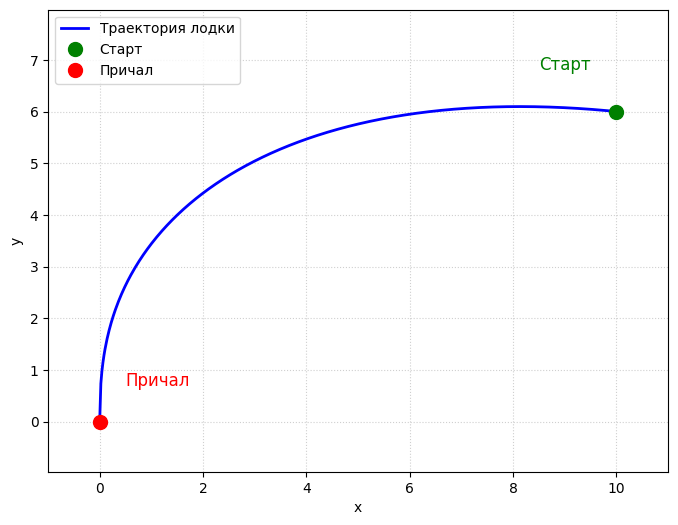

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

u, v = 5, 3
x0, y0 = 10, 6
k = v / u

def y_trajectory(x, k, x0, y0):
    return x * np.sinh(k * np.log(x0 / x) + np.arcsinh(y0 / x0)) #y(x)

x_vals = np.linspace(1e-4, x0, 500) # массив
y_vals = y_trajectory(x_vals, k, x0, y0)

plt.figure(figsize=(8, 6))
plt.plot(x_vals, y_vals, 'b-', linewidth=2, label='Траектория лодки')
plt.plot(x0, y0, 'go', markersize=10, label='Старт')
plt.plot(0, 0, 'ro', markersize=10, label='Причал')
plt.text(x0 - 1.5, y0 + 0.8, 'Старт', fontsize=12, color='green')
plt.text(0.5, 0.7, 'Причал', fontsize=12, color='red')

plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.axis('equal')
plt.xlim(-1, x0 + 1)
plt.ylim(-1, max(y0, 8))

plt.show()

